### Connecting Kaggle

In [ ]:
import kagglehub
import os

In [ ]:
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
os.environ['KAGGLEHUB_CACHE'] = "./data"

In [ ]:
path = kagglehub.competition_download("multimodal-cancer-classification-challenge-2026")

100%|██████████| 737M/737M [00:04<00:00, 163MB/s]

Extracting files...


### Importing Necessary Libraries

In [ ]:
!pip install -q timm albumentations
!pip install torchmetrics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 30.1 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
from sklearn.model_selection import train_test_split
# from torchmetrics import
import gc
import cv2
import timm
import random

from tqdm import tqdm
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
import albumentations as A
from albumentations.pytorch import ToTensorV2

### Data Analysis

In [ ]:
print(os.listdir(path))

['sampleSubmission.csv', 'FL', 'train.csv', 'BF']


In [ ]:
labels = pd.read_csv(os.path.join(path, 'train.csv'))
labels.head()

,Name,Diagnosis
0,pat_03_image_1.jpg,1
1,pat_03_image_2.jpg,1
2,pat_03_image_3.jpg,1
3,pat_03_image_4.jpg,1
4,pat_03_image_5.jpg,1


In [ ]:
labels['Diagnosis'].value_counts()

,count
Diagnosis,
0,70000
1,44302


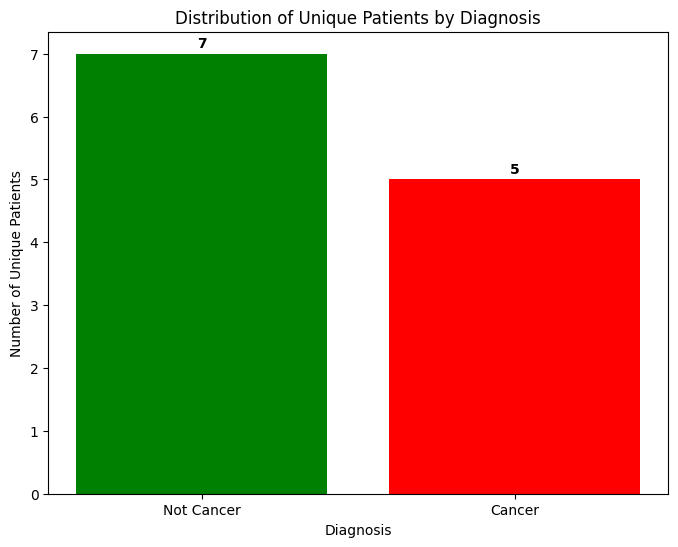

Total unique patients: 12
Diagnosis
Not Cancer    7
Cancer        5
Name: count, dtype: int64


In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt

# Extract Patient ID from the 'Name' column if not already present
# Pattern assumes 'pat_XX_image_YY.jpg'
labels['Patient'] = labels['Name'].apply(lambda x: re.match(r'(pat_\d+)', x).group(1))

# Get the diagnosis per patient (assuming one diagnosis per patient)
patient_diagnosis = labels.groupby('Patient')['Diagnosis'].first().reset_index()

# Count the number of patients for each diagnosis
diagnosis_counts = patient_diagnosis['Diagnosis'].value_counts().sort_index()

# Plotting
plt.figure(figsize=(8, 6))
colors = ['green', 'red']
labels_map = {0: 'Not Cancer', 1: 'Cancer'}
diagnosis_names = [labels_map[i] for i in diagnosis_counts.index]

plt.bar(diagnosis_names, diagnosis_counts.values, color=colors[:len(diagnosis_counts)])
plt.xlabel('Diagnosis')
plt.ylabel('Number of Unique Patients')
plt.title('Distribution of Unique Patients by Diagnosis')

# Add count labels on top of bars
for i, count in enumerate(diagnosis_counts.values):
    plt.text(i, count + 0.1, str(count), ha='center', fontweight='bold')

plt.show()

print(f"Total unique patients: {len(patient_diagnosis)}")
print(diagnosis_counts.rename(index=labels_map))

In [ ]:
num_patients = labels['Patient'].nunique()
print(f"There are {num_patients} unique patients in the dataset.")

There are 12 unique patients in the dataset.


Visualizing samples with labels from train.csv:


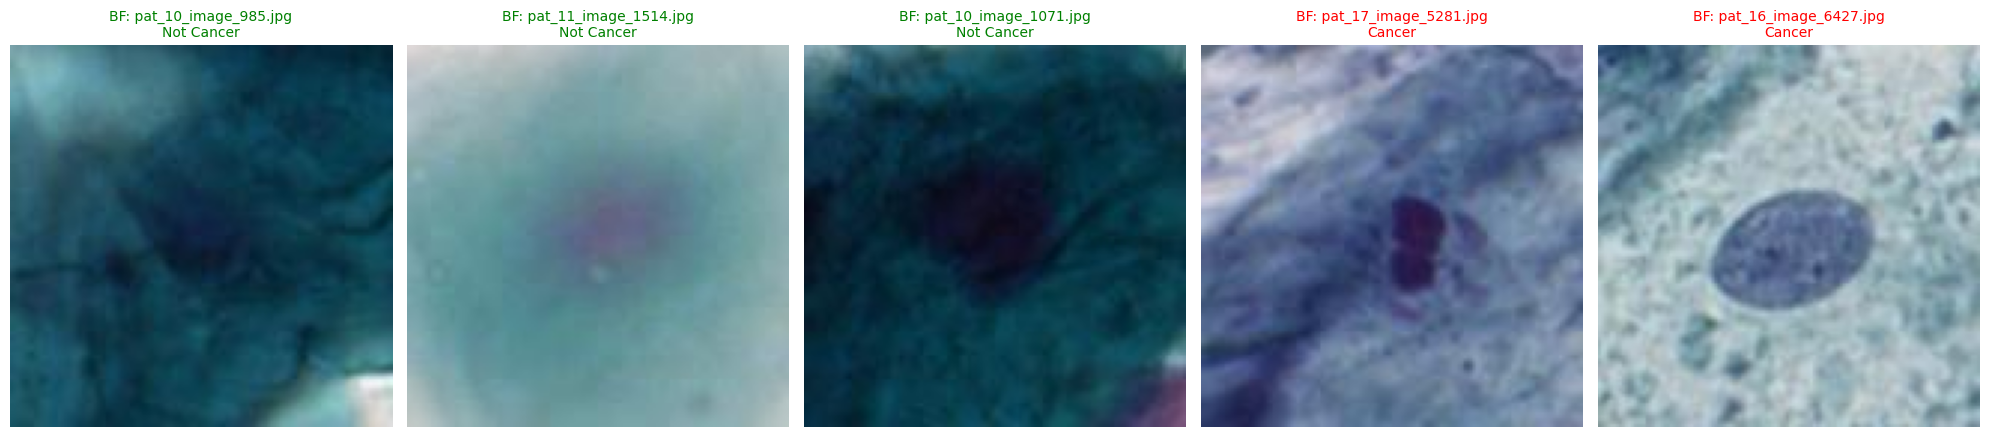

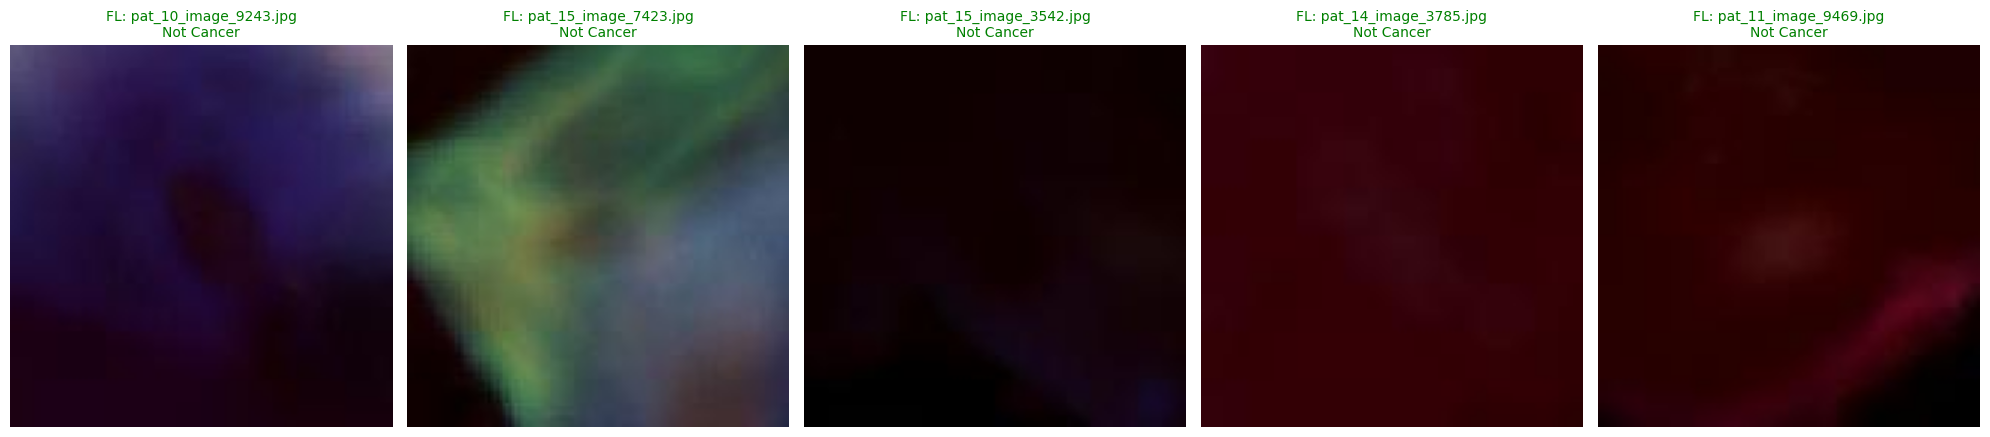

In [ ]:
# Load the latest labels from the competition directory
labels_path = os.path.join(path, 'train.csv')
train_df = pd.read_csv(labels_path)

# Define paths for Bright Field and Fluorescence training images
BF_Images = os.path.join(path, 'BF', 'train')
FL_Images = os.path.join(path, 'FL', 'train')

# Mapping for human-readable titles
diagnosis_map = {0: 'Not Cancer', 1: 'Cancer'}

# Get lists of available image files
BF_Images_list = [f for f in os.listdir(BF_Images) if f.lower().endswith(('.jpg'))]
FL_Images_list = [f for f in os.listdir(FL_Images) if f.lower().endswith(('.jpg'))]

random.shuffle(BF_Images_list)
random.shuffle(FL_Images_list)

def plot_labeled_samples(img_list, base_path, title_prefix):
    fig, ax = plt.subplots(1, 5, figsize=(20, 5))
    for i in range(5):
        img_name = img_list[i]
        img_path = os.path.join(base_path, img_name)
        img = cv2.imread(img_path)

        # Search for the diagnosis in the train_df based on filename
        match = train_df[train_df['Name'] == img_name]
        if not match.empty:
            label_val = match.iloc[0]['Diagnosis']
            label_text = diagnosis_map.get(label_val, 'Unknown')
        else:
            label_text = "Not Found in CSV"

        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax[i].imshow(img)
            title_color = 'red' if label_text == 'Cancer' else 'green' if label_text == 'Not Cancer' else 'black'
            ax[i].set_title(f"{title_prefix}: {img_name}\n{label_text}", color=title_color, fontsize=10)
        ax[i].axis("off")
    plt.tight_layout()
    plt.show()

print("Visualizing samples with labels from train.csv:")
plot_labeled_samples(BF_Images_list, BF_Images, "BF")
plot_labeled_samples(FL_Images_list, FL_Images, "FL")

### Data Preparations

### Patient-level Splitting with GroupKFold
To prevent data leakage, we must ensure that all images belonging to a single patient stay within the same fold.

In [ ]:
import re

# Extract Patient ID from the 'Name' column (e.g., 'pat_03_image_1.jpg' -> 'pat_03')
train_df['Patient'] = train_df['Name'].apply(lambda x: re.match(r'(pat_\d+)', x).group(1))

# Initialize GroupKFold
gkf = GroupKFold(n_splits=5)
train_df['fold'] = -1

for fold, (train_idx, val_idx) in enumerate(gkf.split(train_df, train_df['Diagnosis'], groups=train_df['Patient'])):
    train_df.loc[val_idx, 'fold'] = fold

print(f"Fold distribution:\n{train_df['fold'].value_counts()}")
print(f"Unique patients per fold check:\n{train_df.groupby('fold')['Patient'].nunique()}")

Fold distribution:
fold
0    30000
1    24302
4    20000
3    20000
2    20000
Name: count, dtype: int64
Unique patients per fold check:
fold
0    3
1    3
2    2
3    2
4    2
Name: Patient, dtype: int64


In [ ]:
import pandas as pd

# Ensure we use the labels dataframe which has the patient and fold info
if 'labels' in globals() and 'fold' in labels.columns:
    df_to_check = labels
elif 'train_df' in globals() and 'fold' in train_df.columns:
    df_to_check = train_df
else:
    df_to_check = None

if df_to_check is not None:
    # Check if each patient belongs to only one fold
    patient_fold_counts = df_to_check.groupby('Patient')['fold'].nunique()
    is_valid_split = (patient_fold_counts == 1).all()

    # print(f"Is every patient assigned to exactly one fold? {is_valid_split}")

    # Display the mapping of Patient to Fold
    patient_to_fold = df_to_check.groupby(['Patient', 'fold']).size().reset_index(name='Image_Count')
    display(patient_to_fold)

    # Summary of how many patients are in each fold
    fold_summary = patient_to_fold.groupby('fold')['Patient'].count()
    print('\nNumber of patients per fold:')
    print(fold_summary)
else:
    print('Error: Could not find a dataframe with fold assignments. Please ensure the GroupKFold cell has been executed.')

,Patient,fold,Image_Count
0,pat_03,0,10000
1,pat_05,1,4302
2,pat_07,4,10000
3,pat_09,3,10000
4,pat_10,2,10000
5,pat_11,1,10000
6,pat_13,0,10000
7,pat_14,4,10000
8,pat_15,3,10000
9,pat_16,2,10000



Number of patients per fold:
fold
0    3
1    3
2    2
3    2
4    2
Name: Patient, dtype: int64


### Multimodal PyTorch Dataset
This class will load both the Bright Field and Fluorescence images for a given filename.

In [ ]:
class MultimodalCancerDataset(Dataset):
    def __init__(self, df, bf_dir, fl_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.bf_dir = bf_dir
        self.fl_dir = fl_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Name']
        label = torch.tensor(self.df.loc[idx, 'Diagnosis'], dtype=torch.long)

        # Load BF Image
        bf_path = os.path.join(self.bf_dir, img_name)
        bf_img = cv2.imread(bf_path)
        bf_img = cv2.cvtColor(bf_img, cv2.COLOR_BGR2RGB)

        # Load FL Image
        fl_path = os.path.join(self.fl_dir, img_name)
        fl_img = cv2.imread(fl_path)
        fl_img = cv2.cvtColor(fl_img, cv2.COLOR_BGR2RGB)

        if self.transform:
            # Apply same transforms to both or handle separately
            # For now, we concatenate them to apply multimodal transforms
            augmented_bf = self.transform(image=bf_img)['image']
            augmented_fl = self.transform(image=fl_img)['image']

            # Stack modalities: Shape (6, H, W) or handle as list
            return torch.cat([augmented_bf, augmented_fl], dim=0), label

        return (bf_img, fl_img), label

# Split into train/val for Fold 0
train_idx = train_df[train_df['fold'] != 0].index
valid_idx = train_df[train_df['fold'] == 0].index

train_ds = MultimodalCancerDataset(train_df.loc[train_idx], BF_Images, FL_Images, transform=transforms)
valid_ds = MultimodalCancerDataset(train_df.loc[valid_idx], BF_Images, FL_Images, transform=transforms)

# Set num_workers to 0 to prevent multiprocessing errors observed previously
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=64, shuffle=False, num_workers=0, pin_memory=True)

print(f"Train samples: {len(train_ds)}, Valid samples: {len(valid_ds)}")

In [ ]:
transforms = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406, 0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225, 0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# Split into train/val for Fold 0
train_idx = train_df[train_df['fold'] != 0].index
valid_idx = train_df[train_df['fold'] == 0].index

train_ds = MultimodalCancerDataset(train_df.loc[train_idx], BF_Images, FL_Images, transform=transforms)
valid_ds = MultimodalCancerDataset(train_df.loc[valid_idx], BF_Images, FL_Images, transform=transforms)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train samples: {len(train_ds)}, Valid samples: {len(valid_ds)}")

Train samples: 84302, Valid samples: 30000


### Data Augmentation

In [ ]:
train_transforms = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.4),
    A.VerticalFlip(p=0.4),
    A.RandomRotate90(p=0.4),
    A.Affine(
        scale=(0.9, 1.1),
        translate_percent=(-0.05, 0.05),
        rotate=(-20, 20),
        shear=(-5, 5),
        p=0.5
    ),
    # Fixed: Affine uses translate_percent instead of shift
    # A.Affine(translate_percent=(0, 0.0625), scale=(0.9, 1.1), rotate=(-45, 45), p=0.5),
    # A.OneOf([
    #     # Fixed: Changed std_range to small float values compatible with normalized images
    #     A.GaussNoise(std_range=(0.01, 0.05), p=1.0),
    #     A.GaussianBlur(blur_limit=(3, 7), p=1.0),
    # ], p=0.3),
    # A.ColorJitter(brightness=0.2, contrast=0.2, p=0.3),
    # A.OneOf([
    #     A.RandomBrightnessContrast(brightness_limit=(-0.2, 0.2), contrast_limit=(-0.2, 0.2), p=1.0),
    #     # A.RandomGamma(gamma_limit=(80, 120), p=1.0),
    #     # A.CLAHE(clip_limit=(1, 4), p=1.0),
    #     # A.Sharpen(p=4.0),
    # ], p=0.4),

    A.OneOf([
        A.RandomBrightnessContrast(
            brightness_limit=0.15,
            contrast_limit=0.15,
            p=1.0
        ),

        A.RandomGamma(
            gamma_limit=(90, 110),
            p=1.0
        ),
    ], p=0.3),


    A.GaussianBlur(
        blur_limit=(3, 5),
        p=0.1
    ),

    A.Normalize(mean=(0.485, 0.456, 0.406, 0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225, 0.229, 0.224, 0.225)),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406, 0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225, 0.229, 0.224, 0.225)),
    ToTensorV2(),
])

train_ds.transform = train_transforms
valid_ds.transform = val_transforms

Visualizing augmented training samples...


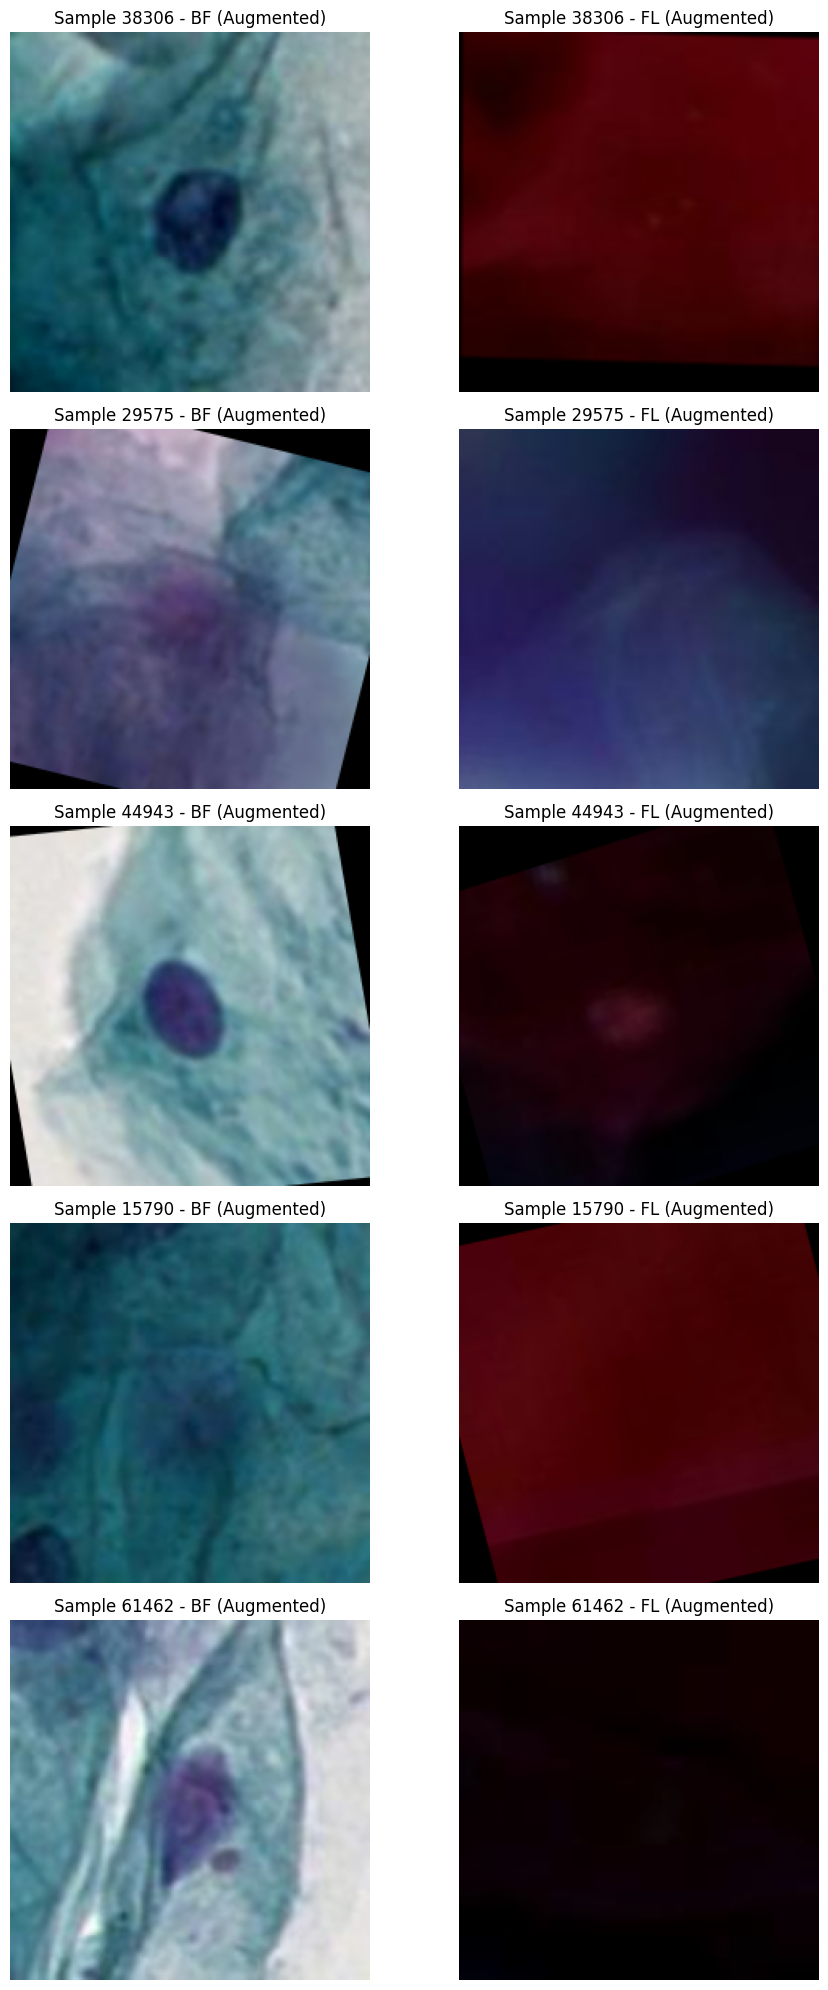

In [ ]:
def visualize_augmentations(dataset, num_samples=5):
    fig, axes = plt.subplots(num_samples, 2, figsize=(10, 4 * num_samples))

    for i in range(num_samples):
        # Get a random sample
        idx = random.randint(0, len(dataset) - 1)
        image_tensor, label = dataset[idx]

        # Unnormalize for visualization
        # Standard ImageNet mean/std
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])

        # Split back to BF and FL (3 channels each)
        bf_img = image_tensor[:3, :, :].permute(1, 2, 0).numpy()
        fl_img = image_tensor[3:, :, :].permute(1, 2, 0).numpy()

        # Clip to [0, 1] range after unnormalizing
        bf_img = np.clip(std * bf_img + mean, 0, 1)
        fl_img = np.clip(std * fl_img + mean, 0, 1)

        axes[i, 0].imshow(bf_img)
        axes[i, 0].set_title(f'Sample {idx} - BF (Augmented)')
        axes[i, 0].axis('off')

        axes[i, 1].imshow(fl_img)
        axes[i, 1].set_title(f'Sample {idx} - FL (Augmented)')
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

print("Visualizing augmented training samples...")
visualize_augmentations(train_ds)

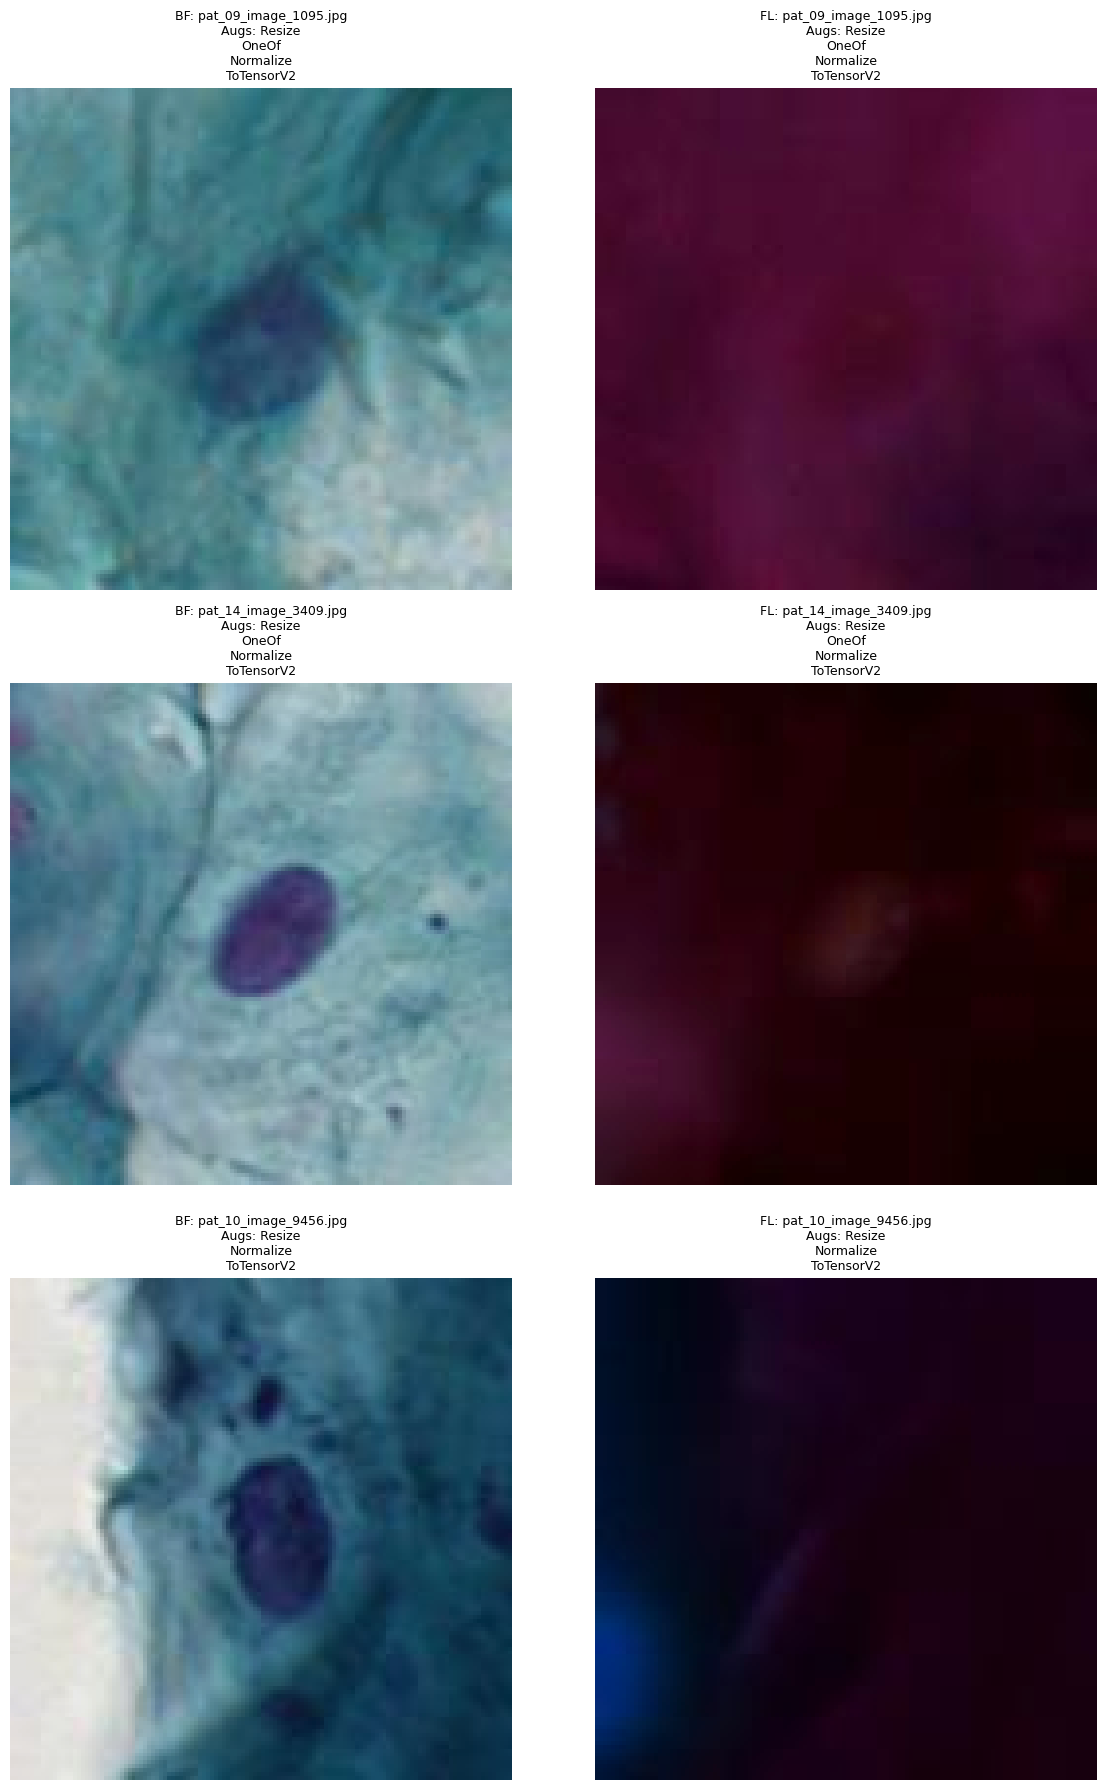

In [ ]:
# def visualize_with_replay(dataset, num_samples=3):
#     # Re-wrap our transforms in ReplayCompose to track what happens
#     replay_transform = A.ReplayCompose(train_transforms.transforms)

#     fig, axes = plt.subplots(num_samples, 2, figsize=(12, 6 * num_samples))

#     mean = np.array([0.485, 0.456, 0.406])
#     std = np.array([0.229, 0.224, 0.225])

#     for i in range(num_samples):
#         idx = random.randint(0, len(dataset.df) - 1)
#         img_name = dataset.df.loc[idx, 'Name']

#         # Load images
#         bf_path = os.path.join(dataset.bf_dir, img_name)
#         bf_raw = cv2.cvtColor(cv2.imread(bf_path), cv2.COLOR_BGR2RGB)
#         fl_path = os.path.join(dataset.fl_dir, img_name)
#         fl_raw = cv2.cvtColor(cv2.imread(fl_path), cv2.COLOR_BGR2RGB)

#         # Apply transform with replay to BF
#         replay_output = replay_transform(image=bf_raw)
#         bf_aug = replay_output['image'].permute(1, 2, 0).numpy()
#         bf_aug = np.clip(std * bf_aug + mean, 0, 1)

#         # Extract applied transform names
#         applied = []
#         for t in replay_output['replay']['transforms']:
#             if t.get('applied', False):
#                 # Get the class name of the transform
#                 name = t['__class_fullname__'].split('.')[-1]
#                 applied.append(name)

#         aug_list_str = "\n".join(applied)

#         # Apply same replay to FL to ensure consistency
#         fl_output = A.ReplayCompose.replay(replay_output['replay'], image=fl_raw)
#         fl_aug = fl_output['image'].permute(1, 2, 0).numpy()
#         fl_aug = np.clip(std * fl_aug + mean, 0, 1)

#         axes[i, 0].imshow(bf_aug)
#         axes[i, 0].set_title(f"BF: {img_name}\nAugs: {aug_list_str}", fontsize=9)
#         axes[i, 0].axis('off')

#         axes[i, 1].imshow(fl_aug)
#         axes[i, 1].set_title(f"FL: {img_name}\nAugs: {aug_list_str}", fontsize=9)
#         axes[i, 1].axis('off')

#     plt.tight_layout()
#     plt.show()

# visualize_with_replay(train_ds)

### Multimodal Model Architecture (Late Fusion)
We use two identical backbones to extract features from BF and FL images independently, then concatenate those features for the final diagnosis.

In [ ]:
class MultimodalModel(nn.Module):
    def __init__(self, model_name='efficientnet_b0', pretrained=True):
        super(MultimodalModel, self).__init__()
        # Backbone for Bright Field modality
        self.backbone_bf = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        # Backbone for Fluorescence modality
        self.backbone_fl = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')

        # Get feature dimension
        num_features = self.backbone_bf.num_features

        # Fusion layer (Late Fusion)
        self.classifier = nn.Sequential(
            nn.Linear(num_features * 2, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 1) # Output logit for Binary Classification
        )

    def forward(self, x):
        # x is expected to be (Batch, 6, H, W)
        # Split into BF (first 3 channels) and FL (last 3 channels)
        x_bf = x[:, :3, :, :]
        x_fl = x[:, 3:, :, :]

        feat_bf = self.backbone_bf(x_bf)
        feat_fl = self.backbone_fl(x_fl)

        # Concatenate features
        combined_features = torch.cat([feat_bf, feat_fl], dim=1)

        # Final classification
        logits = self.classifier(combined_features)
        return logits

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_late = MultimodalModel().to(device)
print(f"Model initialized on {device}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Model initialized on cuda


### Early Fusion Model Architecture
In this version, we modify the first layer of a single backbone to accept 6 channels (3 from BF + 3 from FL).

In [ ]:
class EarlyFusionModel(nn.Module):
    def __init__(self, model_name='efficientnet_b0', pretrained=True):
        super(EarlyFusionModel, self).__init__()
        # Create a single backbone
        self.backbone = timm.create_model(
            model_name,
            pretrained=pretrained,
            num_classes=1,
            in_chans=6 # Modify input layer to accept 6 channels
        )

    def forward(self, x):
        # x is already (Batch, 6, H, W) from our Dataset
        return self.backbone(x)

model_early = EarlyFusionModel().to(device)

### Resnet18 with Early

In [ ]:
class ResNet18EarlyFusion(nn.Module):
    def __init__(self, pretrained=True):
        super(ResNet18EarlyFusion, self).__init__()
        # Initialize resnet18 with 6 input channels instead of 3
        self.backbone = timm.create_model(
            'resnet18',
            pretrained=pretrained,
            num_classes=1,
            in_chans=6
        )

    def forward(self, x):
        # x is (Batch, 6, H, W)
        return self.backbone(x)

# Initialize the ResNet18 model
model_resnet_early = ResNet18EarlyFusion().to(device)
print("ResNet18 Early Fusion model initialized.")

ResNet18 Early Fusion model initialized.


### Vision Transformer Models

In [ ]:
class ViTEarlyFusion(nn.Module):
    def __init__(self, model_name='vit_tiny_patch16_224', pretrained=True):
        super(ViTEarlyFusion, self).__init__()
        # Initialize ViT with 6 input channels
        # Note: ViTs often require specific input sizes (like 224x224)
        self.backbone = timm.create_model(
            model_name,
            pretrained=pretrained,
            num_classes=1,
            in_chans=6
        )

    def forward(self, x):
        # x is (Batch, 6, H, W)
        return self.backbone(x)

# Initialize the ViT model
model_vit_early = ViTEarlyFusion().to(device)
print("ViT Early Fusion model initialized.")

ViT Early Fusion model initialized.


In [ ]:
class SwinDualFusionModel(nn.Module):
    def __init__(self, model_name='swin_tiny_patch4_window7_224', pretrained=True):
        super(SwinDualFusionModel, self).__init__()
        # Twin Swin backbones for BF and FL modalities
        self.backbone_bf = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        self.backbone_fl = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')

        # Swin Tiny avg pool output is usually 768 dims
        num_features = self.backbone_bf.num_features

        self.classifier = nn.Sequential(
            nn.Linear(num_features * 2, 512),
            nn.BatchNorm1d(512),
            nn.GELU(), # Replaced ReLU with GeLU
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def forward(self, x):
        # Split input into BF and FL (3 channels each)
        x_bf = x[:, :3, : , :]
        x_fl = x[:, 3:, : , :]

        feat_bf = self.backbone_bf(x_bf)
        feat_fl = self.backbone_fl(x_fl)

        # Late fusion of Swin features
        combined = torch.cat([feat_bf, feat_fl], dim=1)
        return self.classifier(combined)

# Initialize the Dual Swin model
model_swin_dual = SwinDualFusionModel().to(device)
print("Swin Dual Fusion model initialized with GeLU.")

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Swin Dual Fusion model initialized with GeLU.


### Note on Image Resolution
Vision Transformers often expect a fixed resolution (like 224x224). Since our current pipeline uses 128x128, the `timm` implementation will automatically interpolate the position embeddings, but for optimal performance, you might consider increasing the `Resize` value in your transforms to 224 if memory allows.

### Training and Validation Loop
We define the training logic, using Binary Cross Entropy with Logits as our loss function and tracking metrics like ROC-AUC.

In [ ]:
from torchmetrics.classification import BinaryAUROC, BinaryAccuracy
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    auroc_metric = BinaryAUROC().to(device)

    for images, labels in tqdm(loader, desc="Training"):
        images, labels = images.to(device), labels.to(device).float().view(-1, 1)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        auroc_metric.update(torch.sigmoid(outputs), labels.int())

    return total_loss / len(loader), auroc_metric.compute().item()

def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    auroc_metric = BinaryAUROC().to(device)
    acc_metric = BinaryAccuracy().to(device)

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validation"):
            images, labels = images.to(device), labels.to(device).float().view(-1, 1)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            probs = torch.sigmoid(outputs)
            auroc_metric.update(probs, labels.int())
            acc_metric.update(probs, labels.int())

    return total_loss / len(loader), auroc_metric.compute().item(), acc_metric.compute().item()

# Hyperparameters & Setup
# EPOCHS = 3
# learning_rate = 1e-4
# criterion = nn.BCEWithLogitsLoss()
# optimizer = Adam(model.parameters(), lr=learning_rate)

# for epoch in range(EPOCHS):
#     train_loss, train_auc = train_one_epoch(model, train_loader, optimizer, criterion, device)
#     val_loss, val_auc, val_acc = validate(model, valid_loader, criterion, device)



#     print(f"\nEpoch {epoch+1}/{EPOCHS}")
#     print(f"Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
#     print(f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")

### Training Different models

#### EfficientNET Early

In [ ]:
EPOCHS = 10
learning_rate = 1e-4
criterion = nn.BCEWithLogitsLoss(
    # pos_weight=torch.tensor([1.6]).to(device)
)
# Switched Adam to AdamW
optimizer = AdamW(model_early.parameters(), lr=learning_rate, weight_decay=1e-5)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=1)

best_val_auc = 0

for epoch in range(EPOCHS):
    train_loss, train_auc = train_one_epoch(model_early, train_loader, optimizer, criterion, device)
    val_loss, val_auc, val_acc = validate(model_early, valid_loader, criterion, device)

    scheduler.step(val_auc)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")
    print(f"Current LR: {optimizer.param_groups[0]['lr']}")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save(model_early.state_dict(), 'best_model_efficientB0_early.pth')
        print("*** Best Model Saved ***")

Validation: 100%|██████████| 469/469 [00:42<00:00, 11.10it/s]



Epoch 1/10
Train Loss: 0.7490 | Train AUC: 0.8517
Val Loss: 0.3029 | Val AUC: 0.9592 | Val Acc: 0.8788
Current LR: 0.0001
*** Best Model Saved ***


Validation: 100%|██████████| 469/469 [00:39<00:00, 11.94it/s]



Epoch 2/10
Train Loss: 0.2913 | Train AUC: 0.9395
Val Loss: 0.3082 | Val AUC: 0.9675 | Val Acc: 0.8698
Current LR: 0.0001
*** Best Model Saved ***


Validation: 100%|██████████| 469/469 [00:40<00:00, 11.51it/s]



Epoch 3/10
Train Loss: 0.2369 | Train AUC: 0.9577
Val Loss: 0.3254 | Val AUC: 0.9653 | Val Acc: 0.8573
Current LR: 0.0001


... (10 outputs left out)

Validation: 100%|██████████| 469/469 [00:40<00:00, 11.70it/s]



Epoch 9/10
Train Loss: 0.1287 | Train AUC: 0.9872
Val Loss: 0.6637 | Val AUC: 0.9270 | Val Acc: 0.7689
Current LR: 1.25e-05


Validation: 100%|██████████| 469/469 [00:40<00:00, 11.57it/s]


Epoch 10/10
Train Loss: 0.1263 | Train AUC: 0.9877
Val Loss: 0.8171 | Val AUC: 0.9208 | Val Acc: 0.7493
Current LR: 6.25e-06


#### EfficientB0 Late

In [ ]:
EPOCHS = 10
learning_rate = 1e-4
criterion = nn.BCEWithLogitsLoss()
optimizer = AdamW(model_late.parameters(), lr=learning_rate, weight_decay=1e-5)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=1)

best_val_auc = 0

for epoch in range(EPOCHS):
    train_loss, train_auc = train_one_epoch(model_late, train_loader, optimizer, criterion, device)
    val_loss, val_auc, val_acc = validate(model_late, valid_loader, criterion, device)

    scheduler.step(val_auc)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")
    print(f"Current LR: {optimizer.param_groups[0]['lr']}")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save(model_late.state_dict(), 'best_model_efficientB0_late.pth')
        print("*** Best Model Saved ***")

#### ResnetEarly

In [ ]:
EPOCHS = 10
learning_rate = 1e-4
criterion = nn.BCEWithLogitsLoss()
# Switched Adam to AdamW
optimizer = AdamW(model_resnet_early.parameters(), lr=learning_rate, weight_decay=1e-5)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=1)

best_val_auc = 0

for epoch in range(EPOCHS):
    train_loss, train_auc = train_one_epoch(model_resnet_early, train_loader, optimizer, criterion, device)
    val_loss, val_auc, val_acc = validate(model_resnet_early, valid_loader, criterion, device)

    scheduler.step(val_auc)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")
    print(f"Current LR: {optimizer.param_groups[0]['lr']}")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save(model_resnet_early.state_dict(), 'best_model_resnet_early.pth')
        print("*** Best Model Saved ***")

### Swin Transformer Model

In [ ]:
EPOCHS = 8
learning_rate = 1e-4
criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([1.6]).to(device)
)
optimizer = AdamW(model_swin_dual.parameters(), lr=learning_rate, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

# AMP
# scaler = torch.cuda.amp.GradScaler()
# Dictionary to store metrics for later plotting
history = {
    'train_loss': [], 'train_auc': [],
    'val_loss': [], 'val_auc': [], 'val_acc': []
}

best_val_auc = 0

for epoch in range(EPOCHS):
    train_loss, train_auc = train_one_epoch(model_swin_dual, train_loader, optimizer, criterion, device)
    val_loss, val_auc, val_acc = validate(model_swin_dual, valid_loader, criterion, device)

    scheduler.step(val_auc)

    # Store values in history
    history['train_loss'].append(train_loss)
    history['train_auc'].append(train_auc)
    history['val_loss'].append(val_loss)
    history['val_auc'].append(val_auc)
    history['val_acc'].append(val_acc)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")
    print(f"Current LR: {optimizer.param_groups[0]['lr']}")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save(model_swin_dual.state_dict(), 'best_model_swin_dual.pth')
        print("*** Best Model Saved ***")

### CAFNet

In [ ]:
class CrossAttention(nn.Module):
    def __init__(self, dim, num_heads=8, qkv_bias=False, attn_drop=0., proj_drop=0.):
        super().__init__()
        self.num_heads = num_heads
        head_dim = dim // num_heads
        self.scale = head_dim ** -0.5

        self.q = nn.Linear(dim, dim, bias=qkv_bias)
        self.kv = nn.Linear(dim, dim * 2, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)

    def forward(self, x_q, x_kv):
        B, N, C = x_q.shape
        _, M, _ = x_kv.shape

        q = self.q(x_q).reshape(B, N, self.num_heads, C // self.num_heads).permute(0, 2, 1, 3)
        kv = self.kv(x_kv).reshape(B, M, 2, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        k, v = kv[0], kv[1]

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)

        x = (attn @ v).transpose(1, 2).reshape(B, N, C)
        x = self.proj(x)
        x = self.proj_drop(x)
        return x

class CAFNet(nn.Module):
    def __init__(self, model_name='resnet50', pretrained=True):
        super(CAFNet, self).__init__()
        # Twin ResNet50 backbones. global_pool='' keeps spatial dimensions (B, 2048, 7, 7)
        self.backbone_bf = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='')
        self.backbone_fl = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='')

        # ResNet50 final feature depth is 2048
        embed_dim = self.backbone_bf.num_features

        # Cross-Attention modules for inter-modality fusion
        self.bf_to_fl_attn = CrossAttention(dim=embed_dim)
        self.fl_to_bf_attn = CrossAttention(dim=embed_dim)

        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

        self.avgpool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim * 2, 512),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def forward(self, x):
        # x: [B, 6, 224, 224]
        x_bf = x[:, :3, :, :]
        x_fl = x[:, 3:, :, :]

        # Extract features: [B, 2048, 7, 7]
        feat_bf = self.backbone_bf(x_bf)
        feat_fl = self.backbone_fl(x_fl)

        # Reshape spatial features to tokens: [B, 2048, 7, 7] -> [B, 49, 2048]
        B, C, H, W = feat_bf.shape
        feat_bf = feat_bf.view(B, C, H*W).permute(0, 2, 1)
        feat_fl = feat_fl.view(B, C, H*W).permute(0, 2, 1)

        # Cross-Attention Fusion (Residual connection)
        fused_bf = feat_bf + self.bf_to_fl_attn(self.norm1(feat_bf), self.norm1(feat_fl))
        fused_fl = feat_fl + self.fl_to_bf_attn(self.norm2(feat_fl), self.norm2(feat_bf))

        # Global Pooling [B, 49, 2048] -> [B, 2048]
        out_bf = self.avgpool(fused_bf.transpose(1, 2)).flatten(1)
        out_fl = self.avgpool(fused_fl.transpose(1, 2)).flatten(1)

        # Final concatenation
        out = torch.cat([out_bf, out_fl], dim=1)
        return self.classifier(out)

model_cafnet = CAFNet().to(device)
print("CAFNet initialized with ResNet50 backbones.")

### CAFNet Architecture Verification
Based on the provided PDF and standard CAFNet design:
* **Backbones**: Two ResNet-50s without global pooling to preserve spatial maps ($7 \times 7 \times 2048$).
* **Fusion**: Cross-modal attention allows the BF features to weight the FL features and vice versa.
* **Head**: Global pooling of the fused maps followed by a linear classifier.

**Note**: Ensure that `timm` uses the correct output layer for ResNet-50. The current code uses `.view(B, C, H*W)`, which correctly treats the spatial grid as a sequence of tokens for the attention mechanism.

### CAFNet-Specific Data Augmentations
The paper typically utilizes a specific set of transforms to maintain the spatial correlation between the BF and FL modalities.

In [ ]:
cafnet_train_transforms = A.Compose([
    A.Resize(224, 224),
    # Spatial transforms must be identical for both channels
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=45, p=0.5),

    # Color/Intensity transforms specific to cellular imaging
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2),
        A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=10),
    ], p=0.3),

    A.Normalize(mean=(0.485, 0.456, 0.406, 0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225, 0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# Update the dataset transform for the CAFNet training run
train_ds.transform = cafnet_train_transforms
print("Augmentations updated to CAFNet paper standards.")

In [ ]:
cafnet_val_transforms = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406, 0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225, 0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# Update the validation dataset transform
valid_ds.transform = cafnet_val_transforms
print("Validation transforms (Resize + Normalize) applied to valid_ds.")

NameError: name 'A' is not defined

### Testing

### Inference on Test Set
We will create a dataset for the test files, run the model to get probability scores, and format the output for submission.

In [ ]:
class MultimodalTestDataset(Dataset):
    def __init__(self, test_df, bf_dir, fl_dir, transform=None):
        self.df = test_df.reset_index(drop=True)
        self.bf_dir = bf_dir
        self.fl_dir = fl_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Name']

        # Load BF
        bf_path = os.path.join(self.bf_dir, img_name)
        bf_img = cv2.imread(bf_path)
        bf_img = cv2.cvtColor(bf_img, cv2.COLOR_BGR2RGB)

        # Load FL
        fl_path = os.path.join(self.fl_dir, img_name)
        fl_img = cv2.imread(fl_path)
        fl_img = cv2.cvtColor(fl_img, cv2.COLOR_BGR2RGB)

        if self.transform:
            augmented_bf = self.transform(image=bf_img)['image']
            augmented_fl = self.transform(image=fl_img)['image']
            return torch.cat([augmented_bf, augmented_fl], dim=0), img_name

        return (bf_img, fl_img), img_name

# Load sample submission to get test file names
test_df = pd.read_csv(os.path.join(path, 'sampleSubmission.csv'))

# Note: Assuming test images are in 'BF/test' and 'FL/test'
BF_Test = os.path.join(path, 'BF', 'test')
FL_Test = os.path.join(path, 'FL', 'test')

test_ds = MultimodalTestDataset(test_df, BF_Test, FL_Test, transform=transforms)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)



#### EffB0Early

In [ ]:
model_early.eval()
predictions = []
file_names = []

with torch.no_grad():
    for images, names in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        outputs = model_early(images)
        probs = torch.sigmoid(outputs).cpu().numpy()
        predictions.extend(probs.flatten())
        file_names.extend(names)

# Create submission dataframe
submission = pd.DataFrame({'Name': file_names, 'Diagnosis': predictions})
submission.to_csv('submission_eff_early_fahim.csv', index=False)
print("Submission file saved as submission.csv")
display(submission.head())

Testing: 100%|██████████| 923/923 [01:16<00:00, 11.99it/s]


Submission file saved as submission.csv


,Name,Diagnosis
0,image_1.jpg,0.958643
1,image_2.jpg,0.137416
2,image_3.jpg,0.969091
3,image_4.jpg,0.000115
4,image_5.jpg,0.036473


In [ ]:
model_late.eval()
predictions = []
file_names = []

with torch.no_grad():
    for images, names in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        outputs = model_late(images)
        probs = torch.sigmoid(outputs).cpu().numpy()
        predictions.extend(probs.flatten())
        file_names.extend(names)

# Create submission dataframe
submission = pd.DataFrame({'Name': file_names, 'Diagnosis': predictions})
submission.to_csv('submission_eff_late_fahim.csv', index=False)
print("Submission file saved as submission.csv")
display(submission.head())

In [ ]:
model_resnet_early.eval()
predictions = []
file_names = []

with torch.no_grad():
    for images, names in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        outputs = model_resnet_early(images)
        probs = torch.sigmoid(outputs).cpu().numpy()
        predictions.extend(probs.flatten())
        file_names.extend(names)

# Create submission dataframe
submission = pd.DataFrame({'Name': file_names, 'Diagnosis': predictions})
submission.to_csv('submission_resnet_early_fahim.csv', index=False)
print("Submission file saved as submission.csv")
display(submission.head())